# Empirical conditional CDF grid from 6 months of Binance trades, validated out of sample

*The code was written by an AI assistant (Claude) from my instructions; see [How this was made](../README.md#how-this-was-made).*

**Data period:** the lookup table is built from Binance trades of September 2025 to February 2026 (about 180 days); the out-of-sample test uses my live capture of 9 to 16 March 2026.

**What it is.** For every second in six months of BTCUSDT trades (Sep 2025 to Feb 2026, **828,089,310 trades**), the
notebook records the price move over each of 56 horizons (1 to 300 s, square-root spaced) together with the trailing
60-second realised volatility. The result is a lookup table `cdf_grid[vol bin, time remaining, move]`: the empirical
CDF of the move, in 0.1 bp steps from -100 to +100 bps (grid shape 20 × 56 × 2001, 9 MB). The probability that BTC
finishes above a reference price, given it is now `m` bps above it with `t` seconds left, is read from that CDF
(no parametric assumption, nothing is fitted).

**Test (last two code cells).** On my live capture from March 2026 (not used to build the grid), build pseudo-markets
"is the price t seconds from now above the price 300 s ago?" and score the grid's probabilities, then score two
baselines on the same points: the table without the mirrored copies, and a Normal distribution with each cell's spread.
**Pseudo-markets use a 300 s lookback for every t**, so their Brier scores are *not* comparable across horizons or to
the Polymarket numbers in notebook 02; the point of this test is calibration.

In [1]:
import numpy as np
import pandas as pd
from pathlib import Path
from scipy import stats
import zipfile
import time
import json
import os
try:
    import psutil
    _HAS_PSUTIL = True
except ImportError:
    _HAS_PSUTIL = False
    print("psutil not found — run: pip install psutil")
    print("Memory tracking disabled.")
import tempfile
import matplotlib.pyplot as plt
import gc

def mem_mb():
    """Current process memory in MB."""
    return psutil.Process(os.getpid()).memory_info().rss / 1e6 if _HAS_PSUTIL else 0

def dbg(msg):
    """Debug print with timestamp and memory."""
    print(f'  [{time.strftime("%H:%M:%S")}] [{mem_mb():.0f} MB] {msg}', flush=True)

# ── Paths ─────────────────────────────────────────────────────────────
DATA_DIR = Path('data/binance_monthly_trades')   # BTCUSDT-trades-YYYY-MM.zip from data.binance.vision
SERVER   = Path('data')   # also holds binance_spot/ (live capture); the grid is written to data/clifford/
OUT_DIR  = SERVER / 'clifford'
OUT_DIR.mkdir(exist_ok=True)
TEMP_DIR = Path(tempfile.gettempdir())

# ── t_rem bins ────────────────────────────────────────────────────────
TREM_SQRT_EDGES = np.linspace(1, np.sqrt(300), 56)
TREM_EDGES = np.unique(np.round(TREM_SQRT_EDGES**2).astype(int))
TREM_EDGES = TREM_EDGES[TREM_EDGES >= 1]
N_TREM = len(TREM_EDGES)

# ── RV ────────────────────────────────────────────────────────────────
RV_WINDOW_S = 60
N_RV_BINS   = 20

# ── Symmetry ──────────────────────────────────────────────────────────
# Every move is also counted with its sign flipped, so the grid has no Up or Down bias
# from whatever trend BTC had during Sep 2025 to Feb 2026
SYMMETRIC = True

# ── BPS ───────────────────────────────────────────────────────────────
BPS_MIN  = -100.0
BPS_MAX  = +100.0
BPS_STEP = 0.1
BPS_AXIS = np.arange(BPS_MIN, BPS_MAX + BPS_STEP / 2, BPS_STEP)
N_BPS    = len(BPS_AXIS)

CHUNK_ROWS = 5_000_000

print(f't_rem: {N_TREM} bins ({TREM_EDGES[0]}-{TREM_EDGES[-1]}s)')
print(f'RV: {RV_WINDOW_S}s window, {N_RV_BINS} bins')
print(f'BPS: {N_BPS} bins ({BPS_MIN} to {BPS_MAX}, step {BPS_STEP})')
print(f'Grid: ({N_RV_BINS}, {N_TREM}, {N_BPS}) = {N_RV_BINS*N_TREM*N_BPS*4/1e6:.1f} MB')
print(f'Temp dir: {TEMP_DIR}')
print(f'Baseline memory: {mem_mb():.0f} MB')

zips = sorted(DATA_DIR.glob('*.zip'))
print(f'\nFound {len(zips)} zip files:')
for z in zips:
    print(f'  {z.name}  ({z.stat().st_size/1e6:.0f} MB)')


t_rem: 56 bins (1-300s)
RV: 60s window, 20 bins
BPS: 2001 bins (-100.0 to 100.0, step 0.1)
Grid: (20, 56, 2001) = 9.0 MB
Temp dir: <system temp dir>
Baseline memory: 219 MB

Found 6 zip files:
  BTCUSDT-trades-2025-09.zip  (501 MB)
  BTCUSDT-trades-2025-10.zip  (1047 MB)
  BTCUSDT-trades-2025-11.zip  (1210 MB)
  BTCUSDT-trades-2025-12.zip  (961 MB)
  BTCUSDT-trades-2026-01.zip  (866 MB)
  BTCUSDT-trades-2026-02.zip  (1365 MB)


## Helpers (Extract-to-Disk)

In [2]:
def extract_csv(zip_path):
    """Extract CSV from zip to temp file on disk. Returns path to temp CSV."""
    with zipfile.ZipFile(zip_path) as zf:
        csv_name = [n for n in zf.namelist() if n.endswith('.csv')][0]
        temp_path = TEMP_DIR / csv_name
        with zf.open(csv_name) as src, open(temp_path, 'wb') as dst:
            # Copy in 64 MB chunks to avoid memory spike
            while True:
                buf = src.read(64 * 1024 * 1024)
                if not buf:
                    break
                dst.write(buf)
    return temp_path

def get_time_range(csv_path, chunk_size=CHUNK_ROWS):
    """Pass 1: scan disk file for time range. ~80 MB peak per chunk."""
    t_min = np.iinfo(np.int64).max
    t_max = np.iinfo(np.int64).min
    total = 0
    n_chunks = 0
    reader = pd.read_csv(csv_path, header=None, usecols=[1, 4],
                         names=['price', 'time'],
                         dtype={'price': np.float64, 'time': np.int64},
                         chunksize=chunk_size)
    for chunk in reader:
        t = chunk['time'].values
        if len(t) > 0 and t[0] > 1e15:  # microseconds -> milliseconds
            t = t // 1000
        t_min = min(t_min, t[0])
        t_max = max(t_max, t[-1])
        total += len(t)
        n_chunks += 1
        del chunk, t
    dbg(f'Pass 1 done: {total:,} ticks, {n_chunks} chunks, range {t_min}-{t_max}')
    return t_min, t_max, total

def fill_1s_bars(csv_path, t0, n_bars, chunk_size=CHUNK_ROWS):
    """Pass 2: fill 1s bar array from disk file. ~80 MB peak per chunk."""
    price_1s = np.full(n_bars, np.nan, dtype=np.float64)
    n_chunks = 0
    reader = pd.read_csv(csv_path, header=None, usecols=[1, 4],
                         names=['price', 'time'],
                         dtype={'price': np.float64, 'time': np.int64},
                         chunksize=chunk_size)
    for chunk in reader:
        times = chunk['time'].values
        if len(times) > 0 and times[0] > 1e15:  # microseconds -> milliseconds
            times = times // 1000
        prices = chunk['price'].values
        bar_idx = ((times - t0) / 1000).astype(np.int64)
        bar_idx = np.clip(bar_idx, 0, n_bars - 1)
        price_1s[bar_idx] = prices
        n_chunks += 1
        del chunk, times, prices, bar_idx
    dbg(f'Pass 2 done: {n_chunks} chunks processed')
    return price_1s

def forward_fill_and_gaps(price_1s):
    """Forward fill NaN bars, detect large gaps."""
    n_bars = len(price_1s)
    mask = np.isnan(price_1s)
    nan_count = mask.sum()
    gap_mask = np.zeros(n_bars, dtype=bool)

    if mask.any():
        idx_fill = np.where(~mask, np.arange(n_bars), 0)
        np.maximum.accumulate(idx_fill, out=idx_fill)
        price_1s = price_1s[idx_fill]

        changes = np.diff(mask.astype(np.int8))
        gap_starts = np.where(changes == 1)[0] + 1
        gap_ends = np.where(changes == -1)[0] + 1
        if mask[0]: gap_starts = np.concatenate([[0], gap_starts])
        if mask[-1]: gap_ends = np.concatenate([gap_ends, [n_bars]])
        n_big_gaps = 0
        for gs, ge in zip(gap_starts, gap_ends):
            if ge - gs > 60:
                gap_mask[gs:min(ge + RV_WINDOW_S, n_bars)] = True
                n_big_gaps += 1
        dbg(f'{nan_count:,} NaN bars filled, {n_big_gaps} large gaps (>60s)')
    else:
        dbg('No NaN bars')

    return price_1s, gap_mask

def stream_month(zip_path):
    """Full pipeline: extract -> scan -> fill -> cleanup. Returns (price_1s, gap_mask, n_ticks)."""
    dbg(f'--- Processing {zip_path.name} ---')

    # Extract to disk
    csv_path = extract_csv(zip_path)

    # Pass 1: time range
    t_min, t_max, n_ticks = get_time_range(csv_path)
    n_bars = int((t_max - t_min) / 1000) + 1

    # Pass 2: fill bars
    price_1s = fill_1s_bars(csv_path, t_min, n_bars)

    csv_path.unlink()   # delete the temp file

    # Forward fill
    price_1s, gap_mask = forward_fill_and_gaps(price_1s)

    dbg(f'Month done: {n_ticks:,} ticks -> {n_bars:,} bars')
    return price_1s, gap_mask, n_ticks

def compute_rv(price_1s, window=60):
    """Rolling RV, fully vectorized."""
    log_ret = np.diff(np.log(price_1s))
    sq = log_ret ** 2
    cs = np.cumsum(np.concatenate([[0.0], sq]))
    n = len(log_ret)
    rv = np.full(n, np.nan, dtype=np.float64)
    r = np.arange(window, n)
    # rv[r] uses returns r-window … r-1 (prices up to p[r]), never the move from r to r+1
    rv[r] = np.sqrt(cs[r] - cs[r - window])
    return rv

def fill_histogram(price_1s, rv, gap_mask, rv_edges, trem_edges,
                   bps_min, bps_step, n_bps, n_rv, n_trem, grid, grid_mirror):
    """Vectorized bincount fill."""
    n_bars = len(price_1s)
    flat_size = n_rv * n_trem * n_bps
    grid_flat = grid.reshape(-1)
    mirror_flat = grid_mirror.reshape(-1)
    total_fills = 0

    n_rv_arr = len(rv)
    valid_base = np.ones(n_rv_arr, dtype=bool)
    valid_base[:RV_WINDOW_S] = False
    valid_base[np.isnan(rv)] = False
    gm = gap_mask[1:n_rv_arr + 1] if len(gap_mask) > 1 else np.zeros(n_rv_arr, dtype=bool)
    valid_base &= ~gm

    rv_bin_all = np.clip(
        np.searchsorted(rv_edges, rv, side='right').astype(np.int64),
        0, n_rv - 1
    )

    for ti, trem in enumerate(trem_edges):
        max_start = min(n_bars - trem, n_rv_arr)
        if max_start <= 0:
            continue

        valid = valid_base[:max_start].copy()
        future_gap = gap_mask[np.arange(max_start) + trem]
        valid &= ~future_gap

        idx = np.where(valid)[0]
        if len(idx) == 0:
            continue

        ret_bps = (price_1s[idx + trem] - price_1s[idx]) / price_1s[idx] * 10_000
        bps_bin = np.clip(((ret_bps - bps_min) / bps_step).astype(np.int64), 0, n_bps - 1)
        rv_b = rv_bin_all[idx]
        flat_idx = rv_b * (n_trem * n_bps) + ti * n_bps + bps_bin

        counts = np.bincount(flat_idx, minlength=flat_size)
        grid_flat[:flat_size] += counts[:flat_size].astype(np.int32)

        # Same samples with the sign of the move flipped
        bps_bin_m = np.clip(((-ret_bps - bps_min) / bps_step).astype(np.int64), 0, n_bps - 1)
        flat_idx_m = rv_b * (n_trem * n_bps) + ti * n_bps + bps_bin_m
        counts = np.bincount(flat_idx_m, minlength=flat_size)
        mirror_flat[:flat_size] += counts[:flat_size].astype(np.int32)
        total_fills += len(idx)

        del idx, ret_bps, bps_bin, rv_b, flat_idx, bps_bin_m, flat_idx_m, counts, valid, future_gap

    dbg(f'Histogram done: {total_fills:,} total fills')
    return total_fills

## RV Percentile Calibration

In [5]:
rv_samples = []

print('=== RV Calibration Pass ===\n')
for zi, zp in enumerate(zips):
    print(f'\n[{zi+1}/{len(zips)}]')
    price_1s, gap_mask, n_ticks = stream_month(zp)

    rv = compute_rv(price_1s, RV_WINDOW_S)

    gm = gap_mask[1:len(rv)+1] if len(gap_mask) > 1 else np.zeros(len(rv), dtype=bool)
    valid_rv = rv[(~np.isnan(rv)) & (~gm)]
    rv_samples.append(valid_rv[::100].copy())
    dbg(f'{len(valid_rv):,} valid RV, sampled {len(rv_samples[-1]):,}')

    del price_1s, gap_mask, rv, valid_rv, gm
    gc.collect()

all_rv = np.concatenate(rv_samples)
del rv_samples; gc.collect()

pct_points = np.linspace(0, 100, N_RV_BINS + 1)[1:-1]
RV_EDGES = np.percentile(all_rv, pct_points)

print(f'\nPooled RV: {len(all_rv):,} samples')
print(f'Edges ({len(RV_EDGES)}):')
for i, (lo, hi) in enumerate(zip(
        np.concatenate([[0], RV_EDGES]),
        np.concatenate([RV_EDGES, [np.inf]]))):
    pct = np.mean((all_rv >= lo) & (all_rv < hi)) * 100
    print(f'  Bin {i:>2}: [{lo*10000:>8.3f}, {hi*10000:>8.3f}) bps  ({pct:.1f}%)')

del all_rv; gc.collect()
dbg('RV calibration complete')

=== RV Calibration Pass ===


[1/6]
  [18:02:52] [229 MB] --- Processing BTCUSDT-trades-2025-09.zip ---
  [18:03:56] [233 MB] Pass 1 done: 64,657,874 ticks, 13 chunks, range 1756684800178-1759276799498
  [18:04:36] [254 MB] Pass 2 done: 13 chunks processed
  [18:04:37] [303 MB] 238,028 NaN bars filled, 0 large gaps (>60s)
  [18:04:37] [254 MB] Month done: 64,657,874 ticks -> 2,592,000 bars
  [18:04:37] [298 MB] 2,591,939 valid RV, sampled 25,920

[2/6]
  [18:04:37] [233 MB] --- Processing BTCUSDT-trades-2025-10.zip ---
  [18:08:54] [234 MB] Pass 1 done: 145,191,072 ticks, 30 chunks, range 1759276800181-1761955199599
  [18:11:54] [255 MB] Pass 2 done: 30 chunks processed
  [18:11:58] [306 MB] 173,702 NaN bars filled, 0 large gaps (>60s)
  [18:11:58] [255 MB] Month done: 145,191,072 ticks -> 2,678,400 bars
  [18:11:58] [301 MB] 2,678,339 valid RV, sampled 26,784

[3/6]
  [18:11:58] [234 MB] --- Processing BTCUSDT-trades-2025-11.zip ---
  [18:17:54] [234 MB] Pass 1 done: 169,048,376 ticks

## Build Histogram Grid

In [6]:
grid = np.zeros((N_RV_BINS, N_TREM, N_BPS), dtype=np.int32)          # moves as they happened
grid_mirror = np.zeros((N_RV_BINS, N_TREM, N_BPS), dtype=np.int32)   # the same moves with the sign flipped
total_fills = 0

print('=== Main Grid Build ===\n')
t_all = time.time()

for zi, zp in enumerate(zips):
    print(f'\n[{zi+1}/{len(zips)}]')
    price_1s, gap_mask, n_ticks = stream_month(zp)

    rv = compute_rv(price_1s, RV_WINDOW_S)
    dbg(f'RV computed, {(~np.isnan(rv)).sum():,} valid')

    fills = fill_histogram(
        price_1s, rv, gap_mask, RV_EDGES, TREM_EDGES,
        BPS_MIN, BPS_STEP, N_BPS, N_RV_BINS, N_TREM, grid, grid_mirror
    )
    total_fills += fills

    del price_1s, gap_mask, rv
    gc.collect()
    dbg(f'Month done. Cumulative fills: {total_fills:,}')

total_time = time.time() - t_all
print(f'\n=== Grid Complete ===')
print(f'Total fills: {total_fills:,}')
print(f'Total time: {total_time:.0f}s ({total_time/60:.1f} min)')

ct = grid.sum(axis=2)
print(f'\nCell fills:  min={ct.min():,}  median={int(np.median(ct)):,}  '
      f'mean={int(ct.mean()):,}  max={ct.max():,}')
print(f'Empty cells: {(ct == 0).sum()} / {ct.size}')
clip = grid[:, :, 0].sum() + grid[:, :, -1].sum()
print(f'Clipped: {clip:,} ({clip/max(total_fills,1)*100:.4f}%)')
dbg('Grid build complete')

=== Main Grid Build ===


[1/6]
  [18:50:19] [204 MB] --- Processing BTCUSDT-trades-2025-09.zip ---
  [18:52:38] [204 MB] Pass 1 done: 64,657,874 ticks, 13 chunks, range 1756684800178-1759276799498
  [18:54:07] [225 MB] Pass 2 done: 13 chunks processed
  [18:54:08] [275 MB] 238,028 NaN bars filled, 0 large gaps (>60s)
  [18:54:08] [225 MB] Month done: 64,657,874 ticks -> 2,592,000 bars
  [18:54:08] [246 MB] RV computed, 2,591,939 valid
  [18:54:30] [290 MB] Histogram done: 145,142,652 total fills
  [18:54:31] [222 MB] Month done. Cumulative fills: 145,142,652

[2/6]
  [18:54:31] [222 MB] --- Processing BTCUSDT-trades-2025-10.zip ---
  [19:00:13] [222 MB] Pass 1 done: 145,191,072 ticks, 30 chunks, range 1759276800181-1761955199599
  [19:03:02] [243 MB] Pass 2 done: 30 chunks processed
  [19:03:03] [294 MB] 173,702 NaN bars filled, 0 large gaps (>60s)
  [19:03:03] [243 MB] Month done: 145,191,072 ticks -> 2,678,400 bars
  [19:03:03] [265 MB] RV computed, 2,678,339 valid
  [19:03:14] [291

## Convert to CDFs

In [3]:
# After a restart, reuse the histograms saved by the last full run instead of rebuilding them (about 45 minutes)
if 'grid' not in globals():
    _saved = np.load(OUT_DIR / 'clifford_grid.npz')
    grid, grid_mirror, RV_EDGES = _saved['histogram_grid'], _saved['histogram_grid_mirror'], _saved['rv_edges']
    print('Loaded the histograms saved by the last full run (no rebuild)\n')

# How much Up/Down bias the raw moves carry, pooled over volatility bins.
# Moves are binned in 0.1 bp steps; the two bins next to zero, [-0.1, 0) and [0, 0.1), hold mostly "no change"
# and are left out of both sides, so up means a move of +0.1 bp or more and down a move below -0.1 bp
raw = grid.sum(axis=0).astype(np.float64)
mir = grid_mirror.sum(axis=0).astype(np.float64)
i0 = int(np.argmin(np.abs(BPS_AXIS)))            # the bin [0, 0.1)
p_down = raw[:, :i0 - 1].sum(axis=1) / raw.sum(axis=1)
p_up   = raw[:, i0 + 1:].sum(axis=1) / raw.sum(axis=1)
# Average move: half the difference between the raw and the mirrored histogram, so the binning offsets cancel
mean_move = ((raw - mir) * (BPS_AXIS + BPS_STEP / 2)).sum(axis=1) / raw.sum(axis=1) / 2
print('Raw grid before symmetry (equal up and down = no bias):')
print(f'{"t":>6} {"P(up)":>8} {"P(down)":>8} {"mean move bps":>14}')
for ti in [0, N_TREM // 4, N_TREM // 2, N_TREM - 1]:
    print(f'{TREM_EDGES[ti]:>5}s {p_up[ti]:>8.4f} {p_down[ti]:>8.4f} {mean_move[ti]:>14.3f}')
print()

hist_grid = (grid + grid_mirror) if SYMMETRIC else grid
cdf_grid = np.zeros((N_RV_BINS, N_TREM, N_BPS), dtype=np.float32)

for ri in range(N_RV_BINS):
    for ti in range(N_TREM):
        h = hist_grid[ri, ti].astype(np.float64)
        s = h.sum()
        if s > 0:
            cdf_grid[ri, ti] = (np.cumsum(h) / s).astype(np.float32)
        else:
            cdf_grid[ri, ti] = np.linspace(0, 1, N_BPS).astype(np.float32)

print(f'CDF grid: {cdf_grid.shape}, {cdf_grid.nbytes/1e6:.1f} MB')

def get_q(cdf, bps, ps=[0.01, 0.05, 0.25, 0.50, 0.75, 0.95, 0.99]):
    return [bps[min(np.searchsorted(cdf, p), len(bps)-1)] for p in ps]

show = [
    (0, 0, 'RV=Q1,t=short'),
    (N_RV_BINS-1, 0, 'RV=Q20,t=short'),
    (N_RV_BINS//2, N_TREM//2, 'RV=mid,t=mid'),
    (0, N_TREM-1, 'RV=Q1,t=long'),
    (N_RV_BINS-1, N_TREM-1, 'RV=Q20,t=long'),
]
ps = [0.01, 0.05, 0.25, 0.50, 0.75, 0.95, 0.99]
print(f'\n{"Cell":>20} {"p1":>7} {"p5":>7} {"p25":>7} {"p50":>7} {"p75":>7} {"p95":>7} {"p99":>7} {"N":>10}')
print('-' * 90)
for ri, ti, lbl in show:
    q = get_q(cdf_grid[ri, ti], BPS_AXIS, ps)
    n = grid[ri, ti].sum()   # real samples, not counting the mirrored copies
    print(f'{lbl:>20} {q[0]:>7.2f} {q[1]:>7.2f} {q[2]:>7.2f} {q[3]:>7.2f} '
          f'{q[4]:>7.2f} {q[5]:>7.2f} {q[6]:>7.2f} {n:>10,}')


Loaded the histograms saved by the last full run (no rebuild)

Raw grid before symmetry (equal up and down = no bias):
     t    P(up)  P(down)  mean move bps
    1s   0.1028   0.1038         -0.000
   27s   0.4064   0.4075         -0.007
   87s   0.4666   0.4670         -0.022
  300s   0.4890   0.4928         -0.079

CDF grid: (20, 56, 2001), 9.0 MB

                Cell      p1      p5     p25     p50     p75     p95     p99          N
------------------------------------------------------------------------------------------
       RV=Q1,t=short   -0.10   -0.10   -0.00   -0.00   -0.00   -0.00   -0.00    793,388
      RV=Q20,t=short   -6.00   -3.20   -0.80   -0.00    0.70    3.10    5.90    769,010
        RV=mid,t=mid  -15.50   -9.30   -3.20   -0.00    3.10    9.20   15.40    771,100
        RV=Q1,t=long  -14.50   -8.00   -2.40   -0.00    2.30    7.90   14.40    793,107
       RV=Q20,t=long  -94.00  -55.20  -19.20   -0.00   19.10   55.10   93.90    769,010


### Diagnostics of the built grid

How many samples fall in each (vol bin, time remaining) cell, how the CDF widens with time remaining, and how it widens
with volatility.


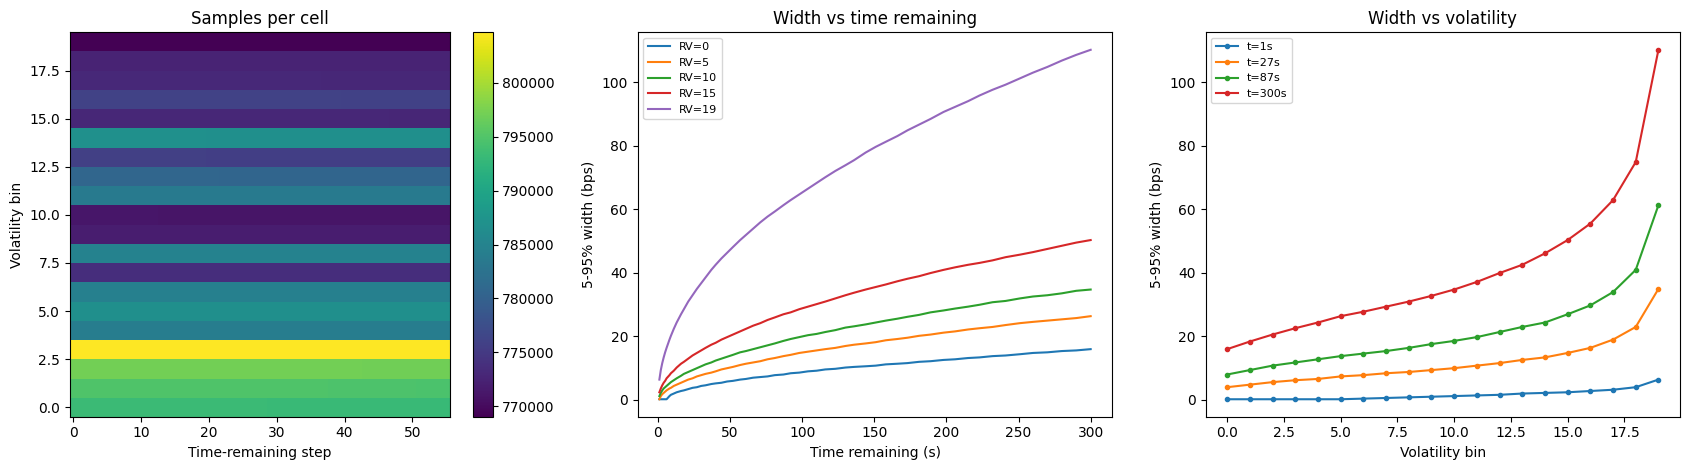

In [4]:
fig, axes = plt.subplots(1, 3, figsize=(17, 4.8))

# 1: real samples per (vol bin, time remaining) cell
ax = axes[0]
im = ax.imshow(grid.sum(axis=2), aspect='auto', origin='lower', cmap='viridis')
ax.set_xlabel('Time-remaining step'); ax.set_ylabel('Volatility bin')
ax.set_title('Samples per cell'); fig.colorbar(im, ax=ax)

def width_bps(ri, ti, lo=0.05, hi=0.95):
    cdf = cdf_grid[ri, ti]
    i_lo, i_hi = np.minimum(np.searchsorted(cdf, [lo, hi]), len(BPS_AXIS) - 1)
    return BPS_AXIS[i_hi] - BPS_AXIS[i_lo]

# 2: 5-95% width of the move against time remaining, for a few volatility bins
ax = axes[1]
for ri in [0, N_RV_BINS // 4, N_RV_BINS // 2, 3 * N_RV_BINS // 4, N_RV_BINS - 1]:
    ax.plot(TREM_EDGES, [width_bps(ri, ti) for ti in range(N_TREM)], label=f'RV={ri}')
ax.set_xlabel('Time remaining (s)'); ax.set_ylabel('5-95% width (bps)')
ax.set_title('Width vs time remaining'); ax.legend(fontsize=8)

# 3: the same width against volatility bin, for a few time-remaining values
ax = axes[2]
for ti in [0, N_TREM // 4, N_TREM // 2, N_TREM - 1]:
    ax.plot(range(N_RV_BINS), [width_bps(ri, ti) for ri in range(N_RV_BINS)], 'o-', ms=3,
            label=f't={TREM_EDGES[ti]}s')
ax.set_xlabel('Volatility bin'); ax.set_ylabel('5-95% width (bps)')
ax.set_title('Width vs volatility'); ax.legend(fontsize=8)

plt.tight_layout()
plt.savefig('../figures/05_grid_diagnostics.png', dpi=130, bbox_inches='tight')
plt.show()

### What mirroring changes

The real 5-minute moves against the real-plus-mirrored mix the table uses, all volatility bins pooled. The right panel
shows exactly what mirroring removes: for each size of move, the share of real up moves minus down moves.

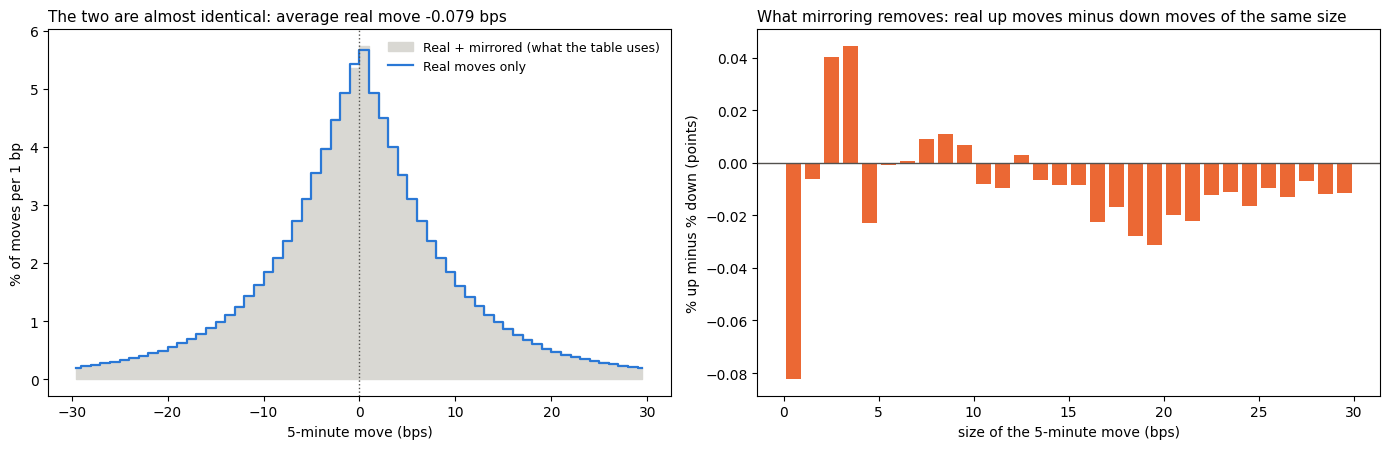

300 s: P(up) 0.4890, P(down) 0.4928, average move -0.079 bps


In [ ]:
# ── Mirroring on the real data: 5-minute moves before and after ─────
# All volatility bins pooled, 300 s horizon, regrouped into 1 bp bins so the shape is readable
ti = N_TREM - 1
raw300 = grid[:, ti].sum(axis=0).astype(np.float64)
mir300 = grid_mirror[:, ti].sum(axis=0).astype(np.float64)
k = 10                                                  # ten 0.1 bp bins per 1 bp bin
n = (N_BPS - 1) // k
x1 = BPS_AXIS[:n * k].reshape(n, k)[:, 0] + k * BPS_STEP / 2
raw1 = raw300[:n * k].reshape(n, k).sum(axis=1) / raw300.sum()
mix1 = (raw300 + mir300)[:n * k].reshape(n, k).sum(axis=1) / (raw300 + mir300).sum()
show = np.abs(x1) <= 30

fig, axes = plt.subplots(1, 2, figsize=(14, 4.6))
ax = axes[0]
ax.fill_between(x1[show], mix1[show] * 100, step='mid', color='#d9d8d3', label='Real + mirrored (what the table uses)')
ax.step(x1[show], raw1[show] * 100, where='mid', color='#2a78d6', lw=1.6, label='Real moves only')
ax.axvline(0, color='#52514e', lw=1, ls=':')
ax.set_xlabel('5-minute move (bps)'); ax.set_ylabel('% of moves per 1 bp')
ax.set_title(f'The two are almost identical: average real move {mean_move[ti]:+.3f} bps', loc='left', fontsize=11)
ax.legend(frameon=False, fontsize=9)

ax = axes[1]
# Leave out the bins [-0.1, 0) and [0, 0.1): they hold mostly moves of exactly zero, which the binning puts on the up side
nz = raw300.copy(); nz[i0 - 1:i0 + 1] = 0
nz1 = nz[:n * k].reshape(n, k).sum(axis=1) / raw300.sum()
xs = x1[show & (x1 > 0)]
up = nz1[show & (x1 > 0)]
down = nz1[show & (x1 < 0)][::-1]                       # the same distance below zero
ax.bar(xs, (up - down) * 100, width=0.8, color='#eb6834')
ax.axhline(0, color='#52514e', lw=1)
ax.set_xlabel('size of the 5-minute move (bps)'); ax.set_ylabel('% up minus % down (points)')
ax.set_title('What mirroring removes: real up moves minus down moves of the same size', loc='left', fontsize=11)
plt.tight_layout()
plt.savefig('../figures/05_mirroring.png', dpi=130, bbox_inches='tight')
plt.show()
print(f'300 s: P(up) {p_up[ti]:.4f}, P(down) {p_down[ti]:.4f}, average move {mean_move[ti]:+.3f} bps')

## Save

In [5]:
sp = OUT_DIR / 'clifford_grid.npz'
np.savez_compressed(sp,
    cdf_grid=cdf_grid, histogram_grid=grid, histogram_grid_mirror=grid_mirror,
    trem_edges=TREM_EDGES, rv_edges=RV_EDGES, bps_axis=BPS_AXIS)

cfg = {
    'rv_window_s': RV_WINDOW_S, 'n_rv_bins': N_RV_BINS, 'symmetric': SYMMETRIC,
    'bps_min': float(BPS_MIN), 'bps_max': float(BPS_MAX), 'bps_step': float(BPS_STEP),
    'trem_edges': TREM_EDGES.tolist(), 'rv_edges': RV_EDGES.tolist(),
    'data_months': [z.name for z in zips],
}
cp = OUT_DIR / 'clifford_config.json'
with open(cp, 'w') as f: json.dump(cfg, f, indent=2)

print(f'Saved:')
print(f'  {sp}  ({sp.stat().st_size/1e6:.1f} MB)')
print(f'  {cp}')
dbg('All done')


Saved:
  data/clifford/clifford_grid.npz  (7.3 MB)
  data/clifford/clifford_config.json
  [20:01:48] [270 MB] All done


## Out-of-sample check on my live Binance capture

The live trades loaded here are the 9 to 16 March 2026 part of my first capture (30,335,329 trades), which was not used to build the grid.

In [6]:
def load_csvs(folder):
    dfs = []
    for f in sorted(Path(folder).glob('*.csv*')):
        try: dfs.append(pd.read_csv(f, on_bad_lines='skip'))
        except: pass
    return pd.concat(dfs, ignore_index=True) if dfs else pd.DataFrame()

dbg('Loading BN live...')
bn_raw = load_csvs(SERVER / 'binance_spot')
bn_raw['local_ms'] = pd.to_numeric(bn_raw['local_ms'], errors='coerce')
bn_raw['price']    = pd.to_numeric(bn_raw['price'],    errors='coerce')
bn_raw = bn_raw.dropna(subset=['local_ms', 'price']).sort_values('local_ms').reset_index(drop=True)
bn_times_live  = bn_raw['local_ms'].values.astype(np.int64)
bn_prices_live = bn_raw['price'].values.astype(np.float64)
del bn_raw; gc.collect()
dbg(f'BN: {len(bn_times_live):,} ticks')

  [20:01:48] [270 MB] Loading BN live...
  [20:02:39] [758 MB] BN: 30,335,329 ticks


  [20:02:40] [759 MB] Building BN 1s bars...
  [20:02:41] [1018 MB] BN bars: 627,659
  [20:02:41] [1018 MB] Running validation...
  [20:03:49] [1088 MB] Done in 68s

 t_rem        N    Brier  Cal.MAE
----------------------------------
    5s  125,412   0.0249   0.0367
   10s  125,412   0.0390   0.0208
   30s  125,412   0.0711   0.0066
   60s  125,412   0.0972   0.0067
  120s  125,412   0.1278   0.0081
  300s  125,412   0.1701   0.0078


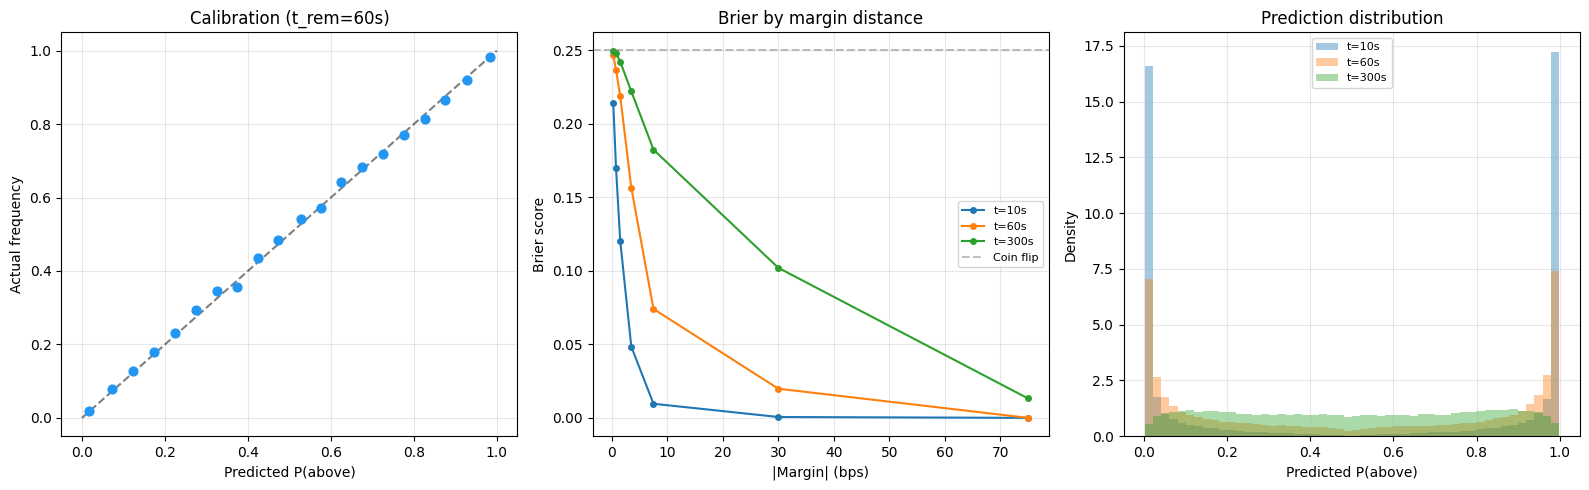


── P(correct) by margin bucket (Binance vs Binance, t_rem=60s) ──
    Margin        N    Brier   Accuracy
----------------------------------------
   0-0.5     5,315   0.2468     55.22%
 0.5-1       5,338   0.2365     60.43%
   1-2      10,265   0.2189     66.96%
   2-5      26,525   0.1565     79.52%
   5-10     31,455   0.0741     91.59%
  10-50     44,571   0.0198     97.91%


In [7]:
# ── Validation: Binance against Binance ──────────────────────────────
# Reference price = BN price from 300s ago (the strike of a pseudo-market)
# Margin = how far BN has moved from that reference
# Query the grid directly
# Check: does BN at t+t_rem still exceed the reference?

def grid_prob_up(margin_bps, t_rem_s, rv_60s, cdf_grid,
                              trem_edges, rv_edges, bps_axis):
    """Query the CDF directly."""
    ti = np.clip(np.searchsorted(trem_edges, t_rem_s, side='right') - 1, 0, len(trem_edges) - 1)
    ri = np.clip(np.searchsorted(rv_edges, rv_60s, side='right'), 0, cdf_grid.shape[0] - 1)

    cdf = cdf_grid[ri, ti].astype(np.float64)
    # cdf[k] is the share of moves below the RIGHT edge of bin k (bins are [a, a + 0.1) bp), so it is read against
    # the right edges. Reading it against the left edges would shift every probability by one bin (see note 4 at the end)
    p_below = np.interp(-margin_bps, bps_axis + (bps_axis[1] - bps_axis[0]), cdf)
    return np.clip(1.0 - p_below, 0.001, 0.999)

# ── Build BN 1s bars from live data ──────────────────────────────────
dbg('Building BN 1s bars...')
bn_t0 = bn_times_live[0]
n_bb = int((bn_times_live[-1] - bn_t0) / 1000) + 1
bi = np.clip(((bn_times_live - bn_t0) / 1000).astype(np.int64), 0, n_bb - 1)
bn_p1s = np.full(n_bb, np.nan)
bn_p1s[bi] = bn_prices_live
m = np.isnan(bn_p1s)
if m.any():
    ff = np.where(~m, np.arange(n_bb), 0)
    np.maximum.accumulate(ff, out=ff)
    bn_p1s = bn_p1s[ff]
bn_rv = compute_rv(bn_p1s, RV_WINDOW_S)
dbg(f'BN bars: {n_bb:,}')

# ── Validation ────────────────────────────────────────────────────────
EVAL_T = [5, 10, 30, 60, 120, 300]
REF_OFFSET = 300  # reference price = BN from 300s ago

res_bn = {t: {'p': [], 'a': [], 'margin': []} for t in EVAL_T}

dbg('Running validation...')
tv = time.time()

# Sample every 5th second, starting after warmup period
start_idx = max(RV_WINDOW_S, REF_OFFSET) + 1

for i in range(start_idx, len(bn_rv) - max(EVAL_T), 5):
    rv = bn_rv[i]
    if np.isnan(rv):
        continue

    bn_now = bn_p1s[i]
    bn_ref = bn_p1s[i - REF_OFFSET]  # pseudo-market strike from 300s ago

    margin_bps = (bn_now - bn_ref) / bn_ref * 10_000

    for tr in EVAL_T:
        bn_future = bn_p1s[i + tr]
        actual = 1.0 if bn_future > bn_ref else 0.0

        p = grid_prob_up(margin_bps, tr, rv, cdf_grid,
                                      TREM_EDGES, RV_EDGES, BPS_AXIS)

        res_bn[tr]['p'].append(p)
        res_bn[tr]['a'].append(actual)
        res_bn[tr]['margin'].append(margin_bps)

dbg(f'Done in {time.time()-tv:.0f}s')

# ── Results ───────────────────────────────────────────────────────────
print(f'\n{"t_rem":>6} {"N":>8} {"Brier":>8} {"Cal.MAE":>8}')
print('-' * 34)

for tr in EVAL_T:
    pr = np.array(res_bn[tr]['p'])
    ac = np.array(res_bn[tr]['a'])
    if len(pr) == 0:
        continue

    brier = np.mean((pr - ac) ** 2)

    bins = np.linspace(0, 1, 11)
    cm = 0; nc = 0
    for b in range(len(bins) - 1):
        mask = (pr >= bins[b]) & (pr < bins[b + 1])
        if mask.sum() > 50:
            cm += abs(pr[mask].mean() - ac[mask].mean())
            nc += 1
    cm /= max(nc, 1)
    print(f'{tr:>5}s {len(pr):>8,} {brier:>8.4f} {cm:>8.4f}')

# ── Calibration plot ──────────────────────────────────────────────────
fig, axes = plt.subplots(1, 3, figsize=(16, 5))

# 1: Calibration curve for t_rem=60
ax = axes[0]
pr60 = np.array(res_bn[60]['p'])
ac60 = np.array(res_bn[60]['a'])
if len(pr60) > 100:
    bins = np.linspace(0, 1, 21)
    pm, am, ns = [], [], []
    for b in range(len(bins) - 1):
        mask = (pr60 >= bins[b]) & (pr60 < bins[b + 1])
        if mask.sum() > 20:
            pm.append(pr60[mask].mean())
            am.append(ac60[mask].mean())
            ns.append(mask.sum())
    ax.plot([0, 1], [0, 1], 'k--', alpha=0.5)
    ax.scatter(pm, am, c='#2196F3', s=40, zorder=5)
    ax.set_xlabel('Predicted P(above)')
    ax.set_ylabel('Actual frequency')
    ax.set_title('Calibration (t_rem=60s)')
ax.grid(True, alpha=0.3)

# 2: Brier by margin bucket
ax = axes[1]
for tr in [10, 60, 300]:
    pr = np.array(res_bn[tr]['p'])
    ac = np.array(res_bn[tr]['a'])
    mg = np.abs(np.array(res_bn[tr]['margin']))

    edges = [0, 0.5, 1, 2, 5, 10, 50, 100]
    briers = []
    centers = []
    for j in range(len(edges) - 1):
        mask = (mg >= edges[j]) & (mg < edges[j + 1])
        if mask.sum() > 50:
            briers.append(np.mean((pr[mask] - ac[mask]) ** 2))
            centers.append((edges[j] + edges[j + 1]) / 2)
    if briers:
        ax.plot(centers, briers, 'o-', label=f't={tr}s', markersize=4)

ax.axhline(0.25, color='gray', linestyle='--', alpha=0.5, label='Coin flip')
ax.set_xlabel('|Margin| (bps)')
ax.set_ylabel('Brier score')
ax.set_title('Brier by margin distance')
ax.legend(fontsize=8)
ax.grid(True, alpha=0.3)

# 3: Prediction distribution
ax = axes[2]
for tr in [10, 60, 300]:
    pr = np.array(res_bn[tr]['p'])
    ax.hist(pr, bins=50, alpha=0.4, label=f't={tr}s', density=True)
ax.set_xlabel('Predicted P(above)')
ax.set_ylabel('Density')
ax.set_title('Prediction distribution')
ax.legend(fontsize=8)
ax.grid(True, alpha=0.3)

plt.tight_layout()
plt.savefig('../figures/05_grid_validation_binance_vs_binance.png', dpi=130, bbox_inches='tight')
plt.show()

# ── Confidence table ──────────────────────────────────────────────────
print(f'\n── P(correct) by margin bucket (Binance vs Binance, t_rem=60s) ──')
pr60 = np.array(res_bn[60]['p'])
ac60 = np.array(res_bn[60]['a'])
mg60 = np.abs(np.array(res_bn[60]['margin']))

print(f'{"Margin":>10} {"N":>8} {"Brier":>8} {"Accuracy":>10}')
print('-' * 40)
for lo, hi in [(0, 0.5), (0.5, 1), (1, 2), (2, 5), (5, 10), (10, 50)]:
    mask = (mg60 >= lo) & (mg60 < hi)
    if mask.sum() > 50:
        b = np.mean((pr60[mask] - ac60[mask]) ** 2)
        # Accuracy: did we predict the right side?
        correct = ((pr60[mask] > 0.5) == (ac60[mask] > 0.5)).mean()
        print(f'{lo:>4}-{hi:<4} {mask.sum():>8,} {b:>8.4f} {correct:>10.2%}')

### Two baselines

The same test points and scores, with two other ways of producing P(Up): the same table built from the real moves
only, without the mirrored copies, which shows what the mirroring changes; and a Normal distribution with mean 0 and
the standard deviation of each cell, which shows whether the table's shape matters or only its spread. The last column
checks that the table's numbers here match the loop above.

In [8]:
# ── Two baselines on the same test points ────────────────────────────
# The same pseudo-markets and scores as above, with three ways of turning (distance from the reference, time left,
# volatility) into P(Up):
#   table      the lookup table used above (the real moves plus their mirrored copies)
#   no mirror  the same table from the real moves only: what the mirrored copies change
#   Normal     a Normal distribution with mean 0 and the standard deviation of each cell: whether the table's shape
#              (its fat tails) matters, or only its spread
# Moves beyond ±100 bps sit in the edge bins, so the Normal's spread is slightly too small in the most volatile cells
# at long horizons.
pts = np.arange(start_idx, len(bn_rv) - max(EVAL_T), 5)
pts = pts[~np.isnan(bn_rv[pts])]                      # the same points as the loop above
ref_t = bn_p1s[pts - REF_OFFSET]
margin_t = (bn_p1s[pts] - ref_t) / ref_t * 10_000
ri_t = np.clip(np.searchsorted(RV_EDGES, bn_rv[pts], side='right'), 0, N_RV_BINS - 1)

cdf_raw = np.cumsum(grid, axis=2, dtype=np.float64)
cdf_raw /= cdf_raw[:, :, -1:]
_h = hist_grid.astype(np.float64)
sd_cell = np.sqrt((_h * (BPS_AXIS + BPS_STEP / 2) ** 2).sum(axis=2) / _h.sum(axis=2))
del _h

right_edges = BPS_AXIS + BPS_STEP
def table_up(cdf, ti):
    # The same reading as grid_prob_up, for all points at once: the share of moves below -margin, on the right edges
    x = np.clip(-margin_t, right_edges[0], right_edges[-1])
    k = np.minimum(((x - right_edges[0]) / BPS_STEP).astype(np.int64), N_BPS - 2)
    w = (x - right_edges[k]) / BPS_STEP
    below = cdf[ri_t, ti, k] * (1 - w) + cdf[ri_t, ti, k + 1] * w
    return np.clip(1.0 - below, 0.001, 0.999)

def scores(p, a):
    # Brier and the calibration error over ten probability bins, as above
    bins = np.linspace(0, 1, 11)
    gaps = []
    for b in range(10):
        m = (p >= bins[b]) & (p < bins[b + 1])
        if m.sum() > 50:
            gaps.append(abs(p[m].mean() - a[m].mean()))
    return np.mean((p - a) ** 2), np.mean(gaps)

print(f'{"":>6}   {"table":^15}   {"no mirror":^15}   {"Normal":^15}')
print(f'{"t_rem":>6}   {"Brier":>7} {"Cal.MAE":>7}   {"Brier":>7} {"Cal.MAE":>7}   {"Brier":>7} {"Cal.MAE":>7}')
print('-' * 62)
for tr in EVAL_T:
    ti = int(np.clip(np.searchsorted(TREM_EDGES, tr, side='right') - 1, 0, N_TREM - 1))
    a = (bn_p1s[pts + tr] > ref_t).astype(np.float64)
    p_tab = table_up(cdf_grid, ti)
    p_raw = table_up(cdf_raw, ti)
    p_nrm = np.clip(stats.norm.cdf(margin_t / sd_cell[ri_t, ti]), 0.001, 0.999)
    row = '   '.join(f'{s[0]:>7.4f} {s[1]:>7.4f}' for s in (scores(p_tab, a), scores(p_raw, a), scores(p_nrm, a)))
    same = np.abs(p_tab - np.array(res_bn[tr]['p'])).max()   # about 0 if this matches the loop above
    print(f'{tr:>5}s   {row}   (vs loop {same:.0e})')

              table           no mirror          Normal     
 t_rem     Brier Cal.MAE     Brier Cal.MAE     Brier Cal.MAE
--------------------------------------------------------------
    5s    0.0249  0.0367    0.0249  0.0362    0.0267  0.0949   (vs loop 7e-14)
   10s    0.0390  0.0208    0.0390  0.0202    0.0401  0.0594   (vs loop 6e-14)
   30s    0.0711  0.0066    0.0711  0.0061    0.0718  0.0348   (vs loop 4e-14)
   60s    0.0972  0.0067    0.0972  0.0066    0.0977  0.0276   (vs loop 2e-14)
  120s    0.1278  0.0081    0.1278  0.0084    0.1284  0.0260   (vs loop 1e-14)
  300s    0.1701  0.0078    0.1701  0.0088    0.1707  0.0220   (vs loop 2e-14)


## Reading the results

* **Calibration is good.** The reliability curve at 60 s remaining lies on the diagonal (left panel); the mean
  absolute calibration gap over ten probability bins is 0.7 percentage points at 30 and 60 s and 0.8 points at 120 and
  300 s. It is weaker at the shortest horizons, 2.1 points at 10 s and 3.7 points at 5 s, which was not investigated.
* Accuracy rises with the margin (60 s left): 55.2% when |margin| < 0.5 bps, 67.0% at 1 to 2 bps, 79.5% at 2 to 5
  bps, 91.6% at 5 to 10 bps, 97.9% above 10 bps.
* **Baselines on the same points.** Without the mirrored copies the scores are almost identical (Brier equal to four
  decimals at every horizon), so on this test the mirroring neither helps nor hurts; it only removes the training months' trend. A
  Normal distribution with each cell's standard deviation scores a slightly worse Brier everywhere (0.0977 against
  0.0972 at 60 s) and a calibration error about three to five times larger from 30 s on (2.8 against 0.7 points at 60 s): the spread
  alone is not enough, the table's fat-tailed shape matters.
* This tests the distribution (Binance vs Binance), not a market. It says nothing about beating a market price.

### Notes on the method

1. **Volatility feature.** `compute_rv` returns, at second `r`, the volatility of the returns `r-60 … r-1`, so the
   feature only sees prices up to second `r` and nothing of the move being predicted.
2. **Volatility bins.** The bin index is `searchsorted(edges, rv)` over the 19 inner percentile edges, so each of the
   20 bins holds 5% of the data.
3. **Up/Down symmetry.** The raw moves come from one six-month stretch, and whatever trend BTC had then would tilt
   P(Up). Every move is also counted with its sign flipped, so a price exactly at the reference reads 50/50. The raw
   drift is printed in the CDF cell; over 5 minutes it is tiny compared with volatility.
4. **Reading a probability.** Moves are stored in bins `[a, a + 0.1)` bp, so the cumulative share up to bin `k` is the
   share of moves below `a + 0.1`. The query therefore interpolates the CDF on the right edges of the bins.
5. The validation samples every 5th second and the horizons overlap, so the effective sample size is far smaller
   than the number of predictions.
